# SING on the GTM study’s R-vines

Fit [upstream SING](https://github.com/baptistar/SING) to **`N_TRAIN` observations** from a known R-vine (10 dimensions by default), then check recovery of its conditional-independence graph. This is one reproducible example, not a Monte Carlo simulation study.

Select the **Python (GTM SING)** kernel in `.venv-sing`. From the repository root, launch with `./sing_experiments/start_jupyter.sh`.

SING estimates $\Omega_{ij}=E[(\partial_i\partial_j\log p(X))^2]$ using a triangular transport map, then thresholds it using a delta-method uncertainty estimate. An edge represents dependence conditional on **all other variables**. It does not recover the vine’s tree representation.

In [151]:
import os
from pathlib import Path
import sys
import time
import json
import importlib.metadata as metadata

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / 'sing_experiments/sing_helpers.py').exists())
os.environ.setdefault('MPLCONFIGDIR', str(ROOT / '.jupyter-sing/matplotlib'))
sys.path.insert(0, str(ROOT))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import networkx as nx
from IPython.display import display
from sing_experiments.sing_helpers import (
    make_rvine, marginal_cdf, nonparanormal_transform, reference_graphs, oracle_mixed_hessians,
    load_sing, FixedOrdering, graph_metrics, SING_COMMIT,
)

print('Python:', sys.executable)
print('SING commit:', SING_COMMIT)
print({p: metadata.version(p) for p in ['TransportMaps', 'numpy', 'pyvinecopulib']})

Python: /Users/matthiasherp/Desktop/phd_github_repositories/gtm/.venv-sing/bin/python
SING commit: 73e1c2ad9a8886854c2ad22c75508ad3cc36df44
{'TransportMaps': '3.2.0', 'numpy': '2.2.6', 'pyvinecopulib': '0.7.3'}


## Configuration

`DIMENSIONALITY` sets the number of variables (at least 2). `ACTIVE_TREES` sets the number of initial dependent trees and must be an integer from 0 to `DIMENSIONALITY - 1`. Trees after that are independence copulas. Use 0 for independent variables, or `DIMENSIONALITY - 1` for a fully active vine.

The defaults `DIMENSIONALITY=10` and `ACTIVE_TREES=3` match the Python GTM generator: trees 1–3 are active and trees 4–9 are independence copulas. Change either setting below, then **restart the kernel and run all cells**. The mixed family sampler is loaded directly from `demos/pyvinecopulib_simulation_helpers.py`, without importing Torch or MLflow. As in that helper, Gaussian/Student parameters are correlations, while the other families convert Kendall’s tau. Consequently `TAU_MEAN` is not a universal lower bound on the realized tau.

`MARGINALS` selects `"gauss"` (standard normal; default), `"exp"` (exponential with rate 1), `"t"` (Student’s t with mean 0, 2.5 degrees of freedom and scale 1), or `"gaussmix"`. The mixture has three equally weighted Gaussian components per variable; each mean is sampled uniformly from [-2, 2] and each component **variance** uniformly from [0.5, 2]. Mixture parameters use `COPULA_SEED` and stay fixed when `SAMPLE_SEED` or `N_TRAIN` changes. Exact parameters are displayed and saved. All choices transform the same copula uniforms through inverse marginal CDFs, preserving the dependency structure.

`NONPARANORMAL_TRANSFORM=True` applies a training-only rank-to-Gaussian transform to **every column**, for all four choices of `MARGINALS`. Each column uses average ranks for ties and `norm.ppf((rank - 0.5) / N_TRAIN)`, keeping the extreme scores finite. SING then receives standardized Gaussian scores in the selected column order. Set the toggle to `False` to standardize the original observations instead. The transform uses only observed training ranks; the generating marginal CDFs remain exclusive to the oracle audit.

`SHUFFLE_VARIABLE_ORDER=True` randomly permutes the data columns once before fitting, using `SHUFFLE_SEED`. Set it to `False` for the original column order. The same chosen order stays fixed across SING iterations. The mapping table records each model position’s original variable number. Both the final scores and the initial ranking scores are mapped back to the original labels before evaluation and plotting. The known vine, oracle audit, and reference graphs keep their original labels.

`ORDER=2` permits nonlinear maps. `DELTA=1` is fixed before looking at truth; increasing it generally removes more edges. Fixed variable ordering avoids CHOLMOD and makes each iteration directly comparable. Map order, variable order, sample size and threshold all affect recovery.

In [152]:
DIMENSIONALITY = 7 #10  # number of variables; must be >= 2
N_TRAIN = 125
COPULA_SEED = 2
SAMPLE_SEED = 2
MARGINALS = "t"  # "gauss", "exp", "t", or "gaussmix"
NONPARANORMAL_TRANSFORM = False  # False uses the original marginal data before standardization
SHUFFLE_VARIABLE_ORDER = True  # False keeps the original data-column order
SHUFFLE_SEED = 3  # independent of copula and sample generation
ACTIVE_TREES = 2#3  # 0 <= ACTIVE_TREES <= DIMENSIONALITY - 1
TAU_MEAN = 0.3
TAU_RANGE = 0.2
ORDER = 3 #2
DELTA = 1.0
BATCH_SIZE = 256
OPTIMIZER_DERIVATIVES = 2  # upstream Newton-CG; 1 selects BFGS
OPTIMIZER_MAXITER = 100

config = dict(dimensionality=DIMENSIONALITY, active_trees=ACTIVE_TREES, n_train=N_TRAIN, copula_seed=COPULA_SEED, sample_seed=SAMPLE_SEED,
              tau_mean=TAU_MEAN, tau_range=TAU_RANGE, marginals=MARGINALS,
              order=ORDER, delta=DELTA, nonparanormal_transform=NONPARANORMAL_TRANSFORM,
              shuffle_variable_order=SHUFFLE_VARIABLE_ORDER, shuffle_seed=SHUFFLE_SEED,
              ordering='shuffled_once_fixed' if SHUFFLE_VARIABLE_ORDER else 'fixed', batch_size=BATCH_SIZE,
              optimizer_derivatives=OPTIMIZER_DERIVATIVES, optimizer_maxiter=OPTIMIZER_MAXITER)
config

{'dimensionality': 7,
 'active_trees': 2,
 'n_train': 125,
 'copula_seed': 2,
 'sample_seed': 2,
 'tau_mean': 0.3,
 'tau_range': 0.2,
 'marginals': 't',
 'order': 3,
 'delta': 1.0,
 'nonparanormal_transform': False,
 'shuffle_variable_order': True,
 'shuffle_seed': 3,
 'ordering': 'shuffled_once_fixed',
 'batch_size': 256,
 'optimizer_derivatives': 2,
 'optimizer_maxiter': 100}

## Parameter count from the parameter Hessian

For the **initial dense SING map**, let $D=\texttt{DIMENSIONALITY}$ and $B=\texttt{ORDER}$. Component $k$ contains an offset $c_k$ expanded in $k-1$ variables up to total degree $B$, and an integrand $h_k$ expanded in $k$ variables up to total degree $B-1$. Consequently,

$$P_c=\sum_{k=1}^{D}\binom{k-1+B}{B}=\binom{D+B}{B+1},
\qquad
P_h=\sum_{k=1}^{D}\binom{k+B-1}{B-1}=\binom{D+B}{B}-1,$$

and Pascal's identity gives

$$P_{\mathrm{SING}}=P_c+P_h=\binom{D+B+1}{B+1}-1.$$

The cell below constructs the same dense map used in SING's first iteration, initialises it to the identity, and evaluates the log-density Hessian **with respect to its coefficients** at one point. The returned tensor has shape $(1,P_{\mathrm{SING}},P_{\mathrm{SING}})$; either of its final two dimensions therefore gives the parameter count. The leading dimension counts evaluation points, and the $P^2$ entries of one Hessian are not $P^2$ separate parameters.

This is a structural check, so no model fit is required. The table compares the Hessian-derived total and the map's separate $c$ and $h$ coefficient counts with the formulas above. The count is independent of `N_TRAIN` and `ACTIVE_TREES`, since the initial map is dense. Later sparse SING iterations may have fewer coefficients.

In [153]:
from math import comb
from TransportMaps.Maps import assemble_IsotropicIntegratedSquaredTriangularTransportMap
from TransportMaps.Distributions import StandardNormalDistribution
from TransportMaps.TransportMapDistributions import PullBackParametricTransportMapDistribution

D, B = DIMENSIONALITY, ORDER
parameter_count_map = assemble_IsotropicIntegratedSquaredTriangularTransportMap(
    D, B, active_vars=None, btype='fun')
parameter_count_map.coeffs = parameter_count_map.get_identity_coeffs()
parameter_count_density = PullBackParametricTransportMapDistribution(
    parameter_count_map, StandardNormalDistribution(D))

# One evaluation point suffices to inspect the coefficient-Hessian dimensions.
parameter_hessian_probe = parameter_count_density.hess_a_log_pdf(np.zeros((1, D)))
parameter_hessian_shape = tuple(parameter_hessian_probe.shape)
P_from_hessian = parameter_hessian_shape[-1]
assert parameter_hessian_shape == (1, P_from_hessian, P_from_hessian)
assert np.isfinite(parameter_hessian_probe).all()

P_c_actual = int(sum(component.c.n_coeffs for component in parameter_count_map.approx_list))
P_h_actual = int(sum(component.h.n_coeffs for component in parameter_count_map.approx_list))
P_c_formula = comb(D + B, B + 1)
P_h_formula = comb(D + B, B) - 1
P_sing_formula = comb(D + B + 1, B + 1) - 1

parameter_count_comparison = pd.DataFrame({
    'Quantity': ['P_c', 'P_h', 'P_SING'],
    'Observed count': [P_c_actual, P_h_actual, P_from_hessian],
    'Dense formula': [P_c_formula, P_h_formula, P_sing_formula],
}).set_index('Quantity')
parameter_count_comparison['Matches'] = (
    parameter_count_comparison['Observed count'] == parameter_count_comparison['Dense formula'])
print(f'D = {D}, B = {B}')
print(f'Parameter-Hessian tensor shape: {parameter_hessian_shape}')
print(f'One parameter Hessian has dimensions: {parameter_hessian_shape[-2:]}')
print(f'P_SING from the Hessian dimensions: {P_from_hessian}')
display(parameter_count_comparison)
assert P_c_actual + P_h_actual == P_from_hessian == int(parameter_count_map.n_coeffs)
assert parameter_count_comparison['Matches'].all()
# Release the probe tensor and temporary map; retain the dimensions and counts.
del parameter_hessian_probe, parameter_count_density, parameter_count_map

D = 7, B = 3
Parameter-Hessian tensor shape: (1, 329, 329)
One parameter Hessian has dimensions: (329, 329)
P_SING from the Hessian dimensions: 329


,Observed count,Dense formula,Matches
Quantity,,,
P_c,210,210,True
P_h,119,119,True
P_SING,329,329,True


In [154]:
vine, data, pair_table = make_rvine(
    dimensionality=DIMENSIONALITY, n=N_TRAIN, copula_seed=COPULA_SEED, sample_seed=SAMPLE_SEED,
    active_trees=ACTIVE_TREES, tau_mean=TAU_MEAN, tau_range=TAU_RANGE, marginals=MARGINALS)
marginal_spec = pair_table.attrs['marginal_spec']
study_graph, scope_graph = reference_graphs(pair_table, dim=DIMENSIONALITY)
assert data.shape == (N_TRAIN, DIMENSIONALITY) and np.isfinite(data).all()
print(vine)
display(pair_table)
print("Marginal specification (original variable order):")
display(marginal_spec)
print('Study-label edges:', study_graph.sum() // 2)
print('Density-factor scope edges:', scope_graph.sum() // 2)
print('References agree:', np.array_equal(study_graph, scope_graph))

<pyvinecopulib.Vinecop> Vinecop model with 7 variables
tree edge conditioned variables conditioning variables var_types       family rotation parameters  df   tau 
   1    1                  4, 3                             c, c     Gaussian        0      -0.34 1.0 -0.22 
   1    2                  6, 7                             c, c       Gumbel      270       1.63 1.0 -0.39 
   1    3                  1, 3                             c, c      Clayton       90       0.99 1.0 -0.33 
   1    4                  2, 7                             c, c      Clayton       90       1.49 1.0 -0.43 
   1    5                  5, 7                             c, c       Gumbel      270       1.67 1.0 -0.40 
   1    6                  3, 7                             c, c       Gumbel       90       1.84 1.0 -0.46 
   2    1                  4, 7                      3      c, c      Clayton       90       1.23 1.0 -0.38 
   2    2                  6, 3                      7      c, c     Gaus

,tree,edge,a,b,conditioning,family,rotation,tau,study_dependence
0,1,1,4,3,(),gaussian,0,-0.218836,1
1,1,2,6,7,(),gumbel,270,-0.387064,1
2,1,3,1,3,(),clayton,90,-0.330885,1
3,1,4,2,7,(),clayton,90,-0.426548,1
4,1,5,5,7,(),gumbel,270,-0.399712,1
5,1,6,3,7,(),gumbel,90,-0.457067,1
6,2,1,4,7,"(3,)",clayton,90,-0.381462,1
7,2,2,6,3,"(7,)",gaussian,0,-0.262709,1
8,2,3,1,7,"(3,)",gumbel,0,0.323239,1
9,2,4,2,3,"(7,)",frank,0,-0.419349,1


Marginal specification (original variable order):


{'kind': 't', 'df': 2.5, 'loc': 0.0, 'scale': 1.0}

Study-label edges: 11
Density-factor scope edges: 11
References agree: True


## Variable order used by SING

`variable_order[j]` is the original zero-based variable index placed in model column `j`. `inverse_variable_order[i]` is the model position of original variable `i`. A local random generator makes the shuffle reproducible without changing the generated vine or observations. The displayed mapping uses 1-based labels.


In [155]:
variable_order = (np.random.default_rng(SHUFFLE_SEED).permutation(DIMENSIONALITY)
                  if SHUFFLE_VARIABLE_ORDER else np.arange(DIMENSIONALITY))
inverse_variable_order = np.argsort(variable_order)
assert np.array_equal(variable_order[inverse_variable_order], np.arange(DIMENSIONALITY))
variable_order_table = pd.DataFrame({
    'model_position': np.arange(1, DIMENSIONALITY + 1),
    'original_variable': variable_order + 1,
})
config['variable_order_1based'] = (variable_order + 1).tolist()
print('Shuffle enabled:', SHUFFLE_VARIABLE_ORDER)
display(variable_order_table)


Shuffle enabled: True


,model_position,original_variable
0,1,6
1,2,7
2,3,3
3,4,2
4,5,5
5,6,4
6,7,1


## First three vine trees of the generating model

Plot the known data-generating R-vine using [pyvinecopulib’s `Vinecop.plot()`](https://vinecopulib.github.io/pyvinecopulib/_generate/pyvinecopulib.Vinecop.plot.html). Only the first three trees are shown (or all available trees if the dimension is below four). Variable labels match the original 1-based indices in `pair_table`, irrespective of the SING column shuffle. An edge label `a,b;S` denotes the pair copula of `a` and `b` conditional on `S`.

The plot titles and `tree` argument use pyvinecopulib’s **zero-based** tree indices: indices below `ACTIVE_TREES` are active; all later trees contain independence copulas. The spring layout uses the existing NetworkX dependency.


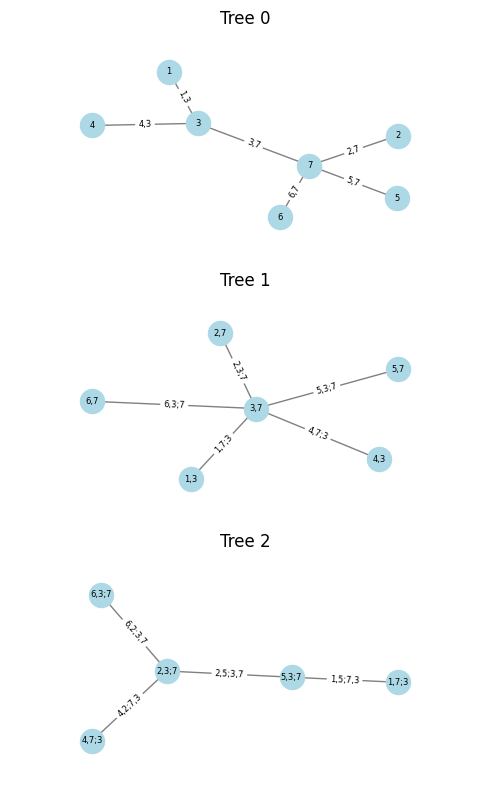

In [156]:
VINE_TREE_INDICES = list(range(min(3, DIMENSIONALITY - 1)))
vine_variable_names = [str(i) for i in range(1, DIMENSIONALITY + 1)]
vine.plot(
    tree=VINE_TREE_INDICES,
    add_edge_labels=True,
    layout='spring_layout',
    vars_names=vine_variable_names,
)


## DAG visualization from the first three trees

Each non-independent conditioned pair `(a, b)` in the displayed trees contributes one edge, colored by its tree. Independence copulas are omitted, and all variables are retained. Arrows run from earlier to later in `vine.order`, which guarantees an acyclic graph. Labels are the original variable numbers, so this picture stays the same when the SING input columns are shuffled.

The arrow directions are a **visualization convention**: this is an acyclic orientation of the pair-edge skeleton, not an inferred causal DAG or a claim of an equivalent Bayesian-network factorization. SING recovery is evaluated against the audited undirected factor-scope graph below, which can also contain connections involving conditioning variables.


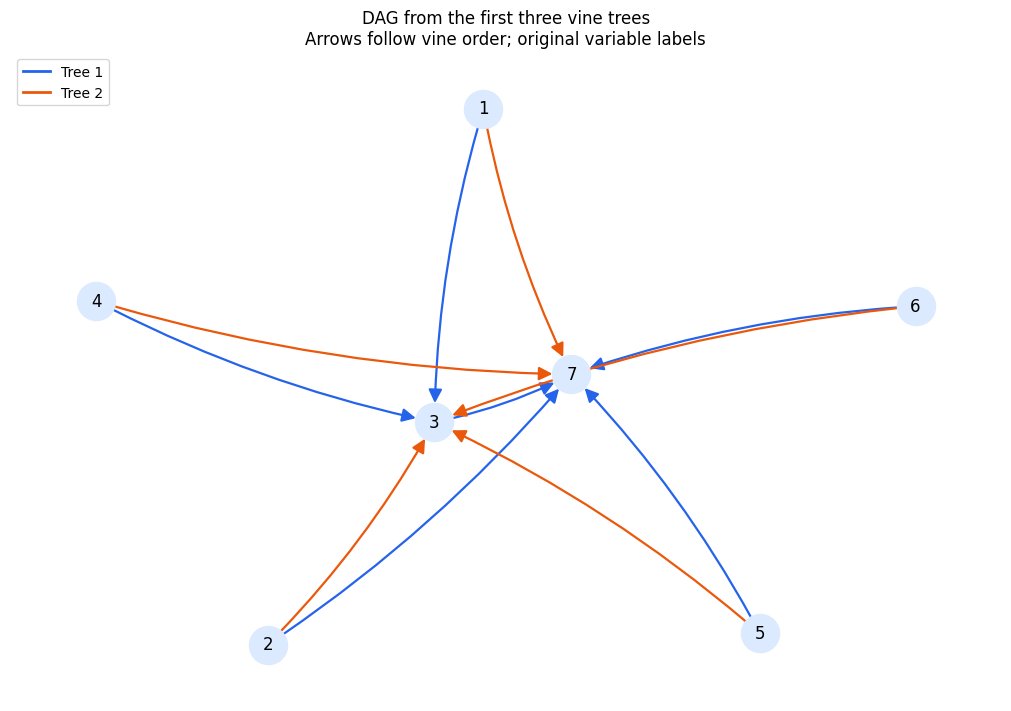

Arrow ordering (original labels): [4, 6, 1, 2, 5, 3, 7]
Non-independent pair edges in the first three trees: 11


In [157]:
dag_order = [int(v) for v in vine.order]
dag_rank = {v: i for i, v in enumerate(dag_order)}
first_three_pairs = pair_table[
    pair_table['tree'].le(len(VINE_TREE_INDICES)) & pair_table['family'].ne('indep')
]
vine_dag = nx.DiGraph()
vine_dag.add_nodes_from(range(1, DIMENSIONALITY + 1))
for pair in first_three_pairs.itertuples():
    source, target = sorted((int(pair.a), int(pair.b)), key=dag_rank.__getitem__)
    vine_dag.add_edge(source, target, tree=int(pair.tree))
assert nx.is_directed_acyclic_graph(vine_dag)
assert vine_dag.number_of_edges() == len(first_three_pairs)

from matplotlib.lines import Line2D
TREE_COLORS = {1: '#2563eb', 2: '#ea580c', 3: '#16a34a'}
# A fixed layout seed keeps the picture independent of the SING shuffle.
dag_positions = nx.spring_layout(vine_dag.to_undirected(), seed=0)
fig, ax = plt.subplots(figsize=(10, 7), constrained_layout=True)
nx.draw_networkx(
    vine_dag, pos=dag_positions, ax=ax,
    node_color='#dbeafe', node_size=750,
    edge_color=[TREE_COLORS[vine_dag.edges[e]['tree']] for e in vine_dag.edges],
    arrows=True, arrowsize=20, width=1.6, connectionstyle='arc3,rad=0.07',
)
ax.legend(handles=[Line2D([0], [0], color=TREE_COLORS[t], lw=2, label=f'Tree {t}')
                   for t in sorted(set(first_three_pairs['tree']))], loc='upper left')
ax.set_title('DAG from the first three vine trees\nArrows follow vine order; original variable labels')
ax.axis('off')
plt.show()
print('Arrow ordering (original labels):', dag_order)
print('Non-independent pair edges in the first three trees:', vine_dag.number_of_edges())


## Audit the reference graph using the known density

The joint log density is a sum of pair-copula log densities evaluated on conditional CDFs. Each non-independent factor can involve both conditioned variables **and its conditioning variables**. Connecting all variables within those scopes gives a conservative graph: omitted edges imply full conditional independence; included edges can disappear through special parameter cancellations.

The study labels use the conditioned pair in each active tree. For this truncated example we check that these labels agree with the factor-scope graph. We also evaluate mixed derivatives of the **true** log density at up to 64 data points in the central 95% of every generating marginal and two finite-difference steps. This audit detects parameter cancellations and indexing errors, but finitely many evaluations cannot prove independence. All univariate marginal log densities contribute zero off-diagonal Hessian terms. The oracle uses the chosen marginal CDFs to evaluate the known copula density in data coordinates. Selecting audit points using marginal quantiles also keeps exponential finite-difference probes inside their support.

These calculations use the oracle only for evaluation; SING receives observations alone.

In [158]:
audit_uniforms = marginal_cdf(data, marginal_spec)
central = data[np.all((audit_uniforms > 0.025) & (audit_uniforms < 0.975), axis=1)][:64]
assert len(central) >= 16, 'Too few central oracle audit points'
steps = [1e-3, 5e-4]
oracle_max = np.stack([
    np.max(np.abs(oracle_mixed_hessians(vine, central, step=h, marginal_spec=marginal_spec)), axis=0)
    for h in steps
])
# A numerical diagnostic cutoff, unrelated to SING's statistical threshold.
ORACLE_CUTOFF = 1e-4
oracle_edges = np.all(oracle_max > ORACLE_CUTOFF, axis=0)
np.fill_diagonal(oracle_edges, False)
indices = np.triu_indices(DIMENSIONALITY, 1)
audit = pd.DataFrame({
    'a': indices[0] + 1, 'b': indices[1] + 1,
    'study_dependence': study_graph[indices],
    'scope_dependence': scope_graph[indices],
    'oracle_max_h_0.001': oracle_max[0][indices],
    'oracle_max_h_0.0005': oracle_max[1][indices],
    'oracle_detected_both_steps': oracle_edges[indices],
})
display(audit)
REFERENCE_AUDIT_OK = np.array_equal(scope_graph, oracle_edges)
print('Factor-scope graph agrees with both oracle checks:', REFERENCE_AUDIT_OK)
if not REFERENCE_AUDIT_OK:
    display(audit[audit.scope_dependence != audit.oracle_detected_both_steps])
    raise RuntimeError('Reference audit inconclusive: inspect oracle tolerance/points before scoring recovery.')
truth = scope_graph.copy()

,a,b,study_dependence,scope_dependence,oracle_max_h_0.001,oracle_max_h_0.0005,oracle_detected_both_steps
0,1,2,False,False,2.220446e-10,8.881784e-10,False
1,1,3,True,True,8.749831e-01,8.749833e-01,True
2,1,4,False,False,2.220446e-10,8.881784e-10,False
3,1,5,False,False,2.220446e-10,8.881784e-10,False
4,1,6,False,False,2.220446e-10,8.881784e-10,False
5,1,7,True,True,2.754824e+00,2.754827e+00,True
6,2,3,True,True,2.973070e+00,2.973073e+00,True
7,2,4,False,False,2.220446e-10,8.881784e-10,False
8,2,5,False,False,2.220446e-10,8.881784e-10,False
9,2,6,False,False,2.220446e-10,8.881784e-10,False


Factor-scope graph agrees with both oracle checks: True


## Fit SING

The optional nonparanormal preprocessing ranks each original training column independently, then applies $z_{ij}=\Phi^{-1}((r_{ij}-0.5)/n)$. Ties share their average rank. This gives empirical Gaussian marginal scores, without assuming a Gaussian copula. A strictly increasing population marginal transform preserves conditional independence; empirical ranks are a finite-sample approximation. With the toggle off, the original marginal observations are used.

The chosen training representation is standardized columnwise, then its columns are optionally shuffled. The original `data`, reference graphs, and oracle audit retain their generating margins and original variable labels. The helper executes the pinned upstream SING source with documented adaptations for TransportMaps 3.2:

- Current parametric pullback fitting API, using the equivalent objective $D_{KL}(T_\sharp\pi\Vert\eta)=D_{KL}(\pi\Vert T^\sharp\eta)$.
- Keep upstream Newton-CG fitting (`ders=2`, maximum 100 iterations); expose BFGS (`ders=1`) as an optional alternative. Optimizer convergence is checked for every component. A precision-loss flag is accepted only when the finite gradient infinity norm is at most `1e-5`; these cases are recorded in the solver diagnostics.
- Replace the removed `np.int` alias with `int` locally in the loaded source.
- Accumulate the original Fisher information and score gradients in batches; solve a linear system instead of explicitly inverting the Fisher matrix.

The iterative sparsification and threshold $\delta\sqrt{\operatorname{Var}(\widehat\Omega_{ij})}\sqrt{\log n}$ remain upstream. The run applies the optional column shuffle once, then holds that order fixed throughout SING. After fitting, both axes of the final score matrix and the initial dense score matrix are restored to original variable order. Fit and derivative calculations can take several minutes.

In [159]:
ORDER = 2

In [160]:
DELTA

1.0

In [161]:
OPTIMIZER_MAXITER=150

In [162]:
# Only observed training ranks enter the optional Gaussianization.
training_data = nonparanormal_transform(data) if NONPARANORMAL_TRANSFORM else data.copy()
center, scale = training_data.mean(axis=0), training_data.std(axis=0)
if not np.isfinite(scale).all() or np.any(scale <= 0):
    raise ValueError("Each training column must have a finite, positive standard deviation")
# Center/scale refer to training_data in original variable order.
processed = ((training_data - center) / scale)[:, variable_order]
preprocessing = dict(
    nonparanormal_transform=NONPARANORMAL_TRANSFORM,
    normal_scores="norm.ppf((average_rank - 0.5) / n_train)" if NONPARANORMAL_TRANSFORM else None,
    fitted_on="training observations only",
    standardization="column mean and standard deviation (ddof=0) of training_data",
)
# Record the actual fitting settings, including overrides in earlier cells.
config.update(nonparanormal_transform=NONPARANORMAL_TRANSFORM, order=ORDER, delta=DELTA,
              optimizer_derivatives=OPTIMIZER_DERIVATIVES, optimizer_maxiter=OPTIMIZER_MAXITER)
print("Nonparanormal transformation enabled:", NONPARANORMAL_TRANSFORM)
sing, history = load_sing(batch_size=BATCH_SIZE, optimizer_derivatives=OPTIMIZER_DERIVATIVES,
                          optimizer_maxiter=OPTIMIZER_MAXITER)
started = time.perf_counter()
recovered_omega_model_order = sing(processed.copy(), ORDER, FixedOrdering(), DELTA)
elapsed_seconds = time.perf_counter() - started
# Restore both matrix axes before thresholding, scoring, and plotting.
original_axes = np.ix_(inverse_variable_order, inverse_variable_order)
recovered_omega = recovered_omega_model_order[original_axes]
recovered_graph = recovered_omega != 0
np.fill_diagonal(recovered_graph, False)
assert np.isfinite(recovered_omega).all()
assert np.array_equal(recovered_graph, recovered_graph.T)
# Initial dense-map scores retain rankings before iterative thresholding.
ranking_scores_model_order = history[0]['omega_raw']
ranking_scores = ranking_scores_model_order[original_axes]
assert np.allclose(recovered_omega[np.ix_(variable_order, variable_order)], recovered_omega_model_order)
assert np.allclose(ranking_scores[np.ix_(variable_order, variable_order)], ranking_scores_model_order)
print(f'Elapsed: {elapsed_seconds:.1f} s; SING iterations: {len(history)}')

# 2000 observations:
# 10:  1.16 sec
# 12:  3.33 sec
# 15:  
# 20 dim stuck in iteration 1 after 77min and not finished

Nonparanormal transformation enabled: False
Problem inputs:

 dimension =  7 
 number of samples =  125 
 polynomial order =  2 
 ordering type =  <class 'sing_experiments.sing_helpers.FixedOrdering'> 
 delta =  1.0 

2026-11-09 11:43:34 WARNING: TransportMaps: Default_IsotropicIntegratedSquaredTriangularTransportMap DEPRECATED since v3.0. Use Maps.assemble_IsotropicIntegratedSquaredTriangularTransportMap instead.
Precision-loss flag accepted: gradient infinity norm meets 1e-5 tolerance.
Map fit converged (7 components); computing Hessian scores.
Computing batched delta-method variance.

SING Iteration:  1
Active variables:  [[np.int64(0)], [np.int64(1)], [np.int64(1), np.int64(2)], [np.int64(1), np.int64(2), np.int64(3)], [np.int64(4)], [np.int64(2), np.int64(5)], [np.int64(6)]] 
  Note variables may be permuted.
Number of edges:  4  out of  21  possible
2026-11-09 11:43:35 WARNING: TransportMaps: Default_IsotropicIntegratedSquaredTriangularTransportMap DEPRECATED since v3.0. Use Maps

## Recovery results

All results below use **original variable labels**, after undoing the input permutation on both score-matrix axes. The pair table also lists each variable’s position in the fitted model.

Score only the `DIMENSIONALITY * (DIMENSIONALITY - 1) / 2` unordered off-diagonal pairs (45 with the default 10 variables). Ranking metrics are reported as NaN if the reference contains only one class, as with zero or all trees active. SHD is the number of missing plus extra edges. Exact recovery means SHD = 0. ROC AUC and average precision use the **initial dense map’s unthresholded scores**; the final graph uses SING’s iterative thresholding. No threshold is selected to maximize agreement with the oracle.

In [163]:
metrics = graph_metrics(truth, recovered_graph, ranking_scores)
display(pd.DataFrame([metrics]))
pair_results = audit.copy()
pair_results['model_position_a'] = inverse_variable_order[pair_results['a'].to_numpy() - 1] + 1
pair_results['model_position_b'] = inverse_variable_order[pair_results['b'].to_numpy() - 1] + 1
pair_results['sing_edge'] = recovered_graph[indices]
pair_results['initial_dense_score'] = ranking_scores[indices]
pair_results['final_thresholded_score'] = recovered_omega[indices]
pair_results['error'] = np.select([
    ~truth[indices] & recovered_graph[indices],
    truth[indices] & ~recovered_graph[indices]], ['false positive', 'false negative'], default='correct')
display(pair_results.sort_values(['error', 'a', 'b']))
if metrics['exact_recovery']:
    print('SING exactly recovered the audited reference graph in this run.')
else:
    print(f"SING did not exactly recover the graph: {metrics['fn']} missed edges and {metrics['fp']} extra edges (SHD={metrics['shd']}).")

,tp,fp,fn,tn,precision,recall,f1,mcc,shd,exact_recovery,roc_auc,average_precision
0,3,0,8,10,1.0,0.272727,0.428571,0.389249,8,False,0.981818,0.986014


,a,b,study_dependence,scope_dependence,oracle_max_h_0.001,oracle_max_h_0.0005,oracle_detected_both_steps,model_position_a,model_position_b,sing_edge,initial_dense_score,final_thresholded_score,error
0,1,2,False,False,2.220446e-10,8.881784e-10,False,7,4,False,1.727544,0.000000,correct
2,1,4,False,False,2.220446e-10,8.881784e-10,False,7,6,False,0.902061,0.000000,correct
3,1,5,False,False,2.220446e-10,8.881784e-10,False,7,5,False,0.487344,0.000000,correct
4,1,6,False,False,2.220446e-10,8.881784e-10,False,7,1,False,0.552704,0.000000,correct
6,2,3,True,True,2.973070e+00,2.973073e+00,True,4,3,True,18.050571,11.305011,correct
7,2,4,False,False,2.220446e-10,8.881784e-10,False,4,6,False,1.577351,0.000000,correct
8,2,5,False,False,2.220446e-10,8.881784e-10,False,4,5,False,0.924969,0.000000,correct
9,2,6,False,False,2.220446e-10,8.881784e-10,False,4,1,False,0.343555,0.000000,correct
10,2,7,True,True,4.966618e+00,4.966627e+00,True,4,2,True,26.063699,20.250201,correct
14,3,7,True,True,6.296267e+00,6.296274e+00,True,3,2,True,43.102949,16.299247,correct


SING did not exactly recover the graph: 8 missed edges and 0 extra edges (SHD=8).


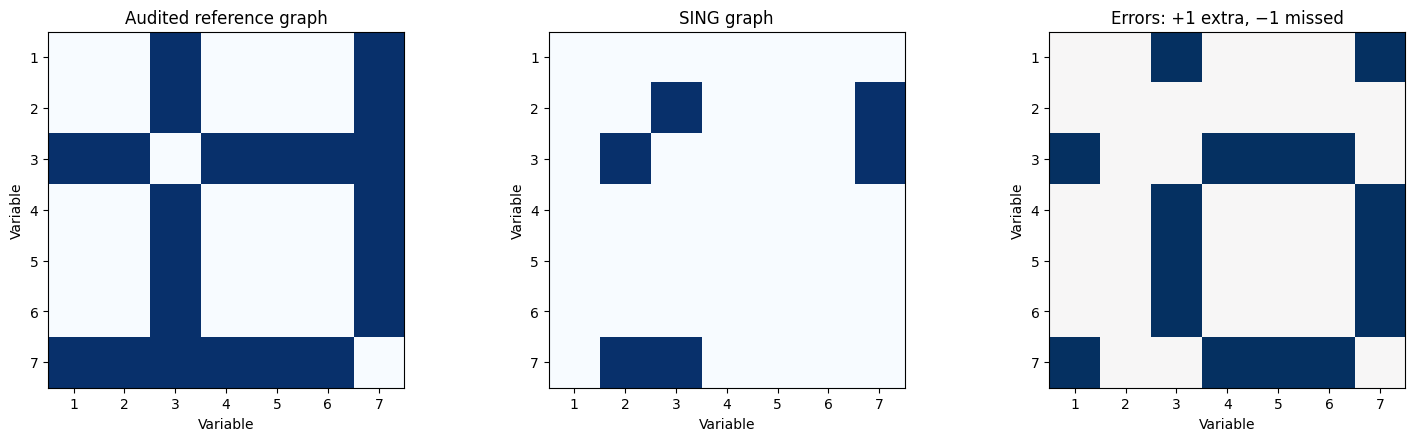

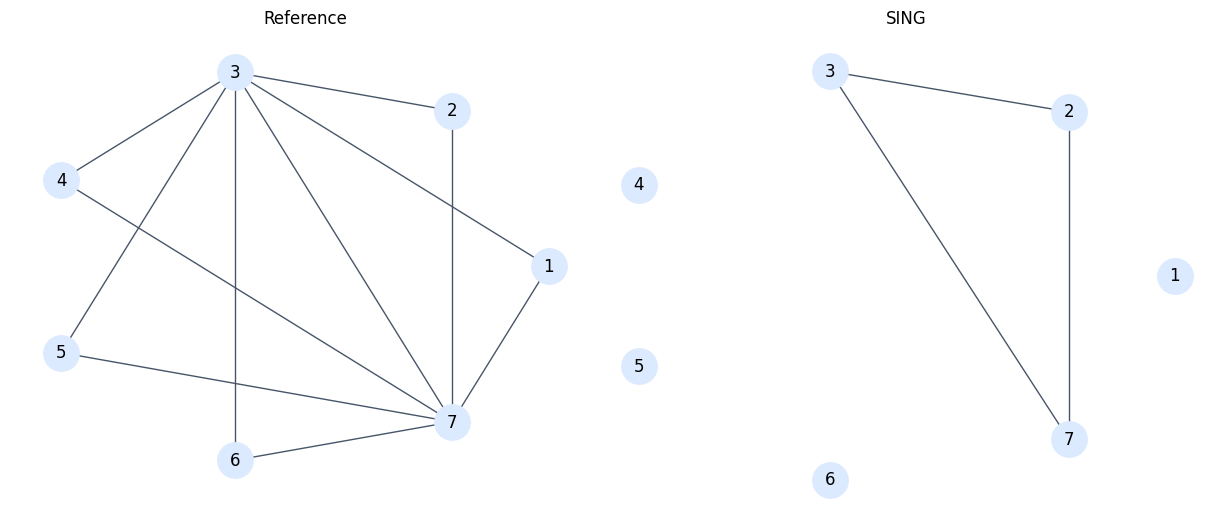

In [164]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.3), constrained_layout=True)
error_matrix = recovered_graph.astype(int) - truth.astype(int)
for ax, matrix, title in zip(axes, [truth, recovered_graph, error_matrix],
        ['Audited reference graph', 'SING graph', 'Errors: +1 extra, −1 missed']):
    ax.imshow(matrix, cmap='RdBu_r' if ax is axes[2] else 'Blues',
              vmin=-1 if ax is axes[2] else 0, vmax=1)
    ax.set(xticks=range(DIMENSIONALITY), yticks=range(DIMENSIONALITY), xticklabels=range(1, DIMENSIONALITY + 1),
           yticklabels=range(1, DIMENSIONALITY + 1), title=title, xlabel='Variable', ylabel='Variable')
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(12, 5), constrained_layout=True)
graph = nx.from_numpy_array(truth)
positions = nx.circular_layout(graph)
for ax, matrix, title in zip(axes, [truth, recovered_graph], ['Reference', 'SING']):
    g = nx.from_numpy_array(matrix)
    nx.draw_networkx(g, pos=positions, ax=ax, labels={i: str(i+1) for i in range(DIMENSIONALITY)},
                     node_color='#dbeafe', edge_color='#475569', node_size=650)
    ax.set_title(title)
    ax.axis('off')
plt.show()

## Save and extend

Results below include the exact vine and marginal specifications, configuration, versions, standardized-data parameters, variable-order mapping, first-three-tree DAG edges, per-pair comparisons and metrics. Saved reference graphs and evaluation scores use original variable order; arrays ending in `_model_order` use the fitted column order. `data` always contains original generated observations. `training_data` contains the optional Gaussian rank scores (or a copy of `data` when disabled), before standardization and shuffling. `center` and `scale` describe `training_data`; these arrays all use original variable order. `processed_model_order` is the exact standardized, shuffled input to SING. The preprocessing specification records the rank formula and tie handling. Separate output directories distinguish marginal choices, preprocessing on/off, ordered runs, and each shuffle seed. The results directory is ignored by Git; this executed notebook preserves the visible results.

Toggle `NONPARANORMAL_TRANSFORM` to compare rank-based and original-data fits. Toggle `SHUFFLE_VARIABLE_ORDER` or change `SHUFFLE_SEED` to assess sensitivity to the fitting order. Restart the kernel and rerun all cells after changes.

For a follow-up, vary `DIMENSIONALITY` and `ACTIVE_TREES` in the configuration cell, `N_TRAIN` across 125, 500 and 2,000, `COPULA_SEED` across multiple vines, or `ORDER` across 1, 2 and 3, then rerun all cells. Higher orders increase derivative costs substantially. Treat comparisons across `DELTA` values as a sensitivity analysis; selecting a threshold using the known graph would be oracle tuning. This single example does not establish performance across the GTM study.

In [165]:
order_suffix = f'shuffle{SHUFFLE_SEED}' if SHUFFLE_VARIABLE_ORDER else 'ordered'
preprocessing_suffix = 'nonparanormal' if NONPARANORMAL_TRANSFORM else 'raw'
output = ROOT / 'sing_experiments/results' / f'rvine{DIMENSIONALITY}_trees{ACTIVE_TREES}_n{N_TRAIN}_copula{COPULA_SEED}_sample{SAMPLE_SEED}_p{ORDER}_delta{DELTA:g}_{order_suffix}_marginals{MARGINALS}_{preprocessing_suffix}'
output.mkdir(parents=True, exist_ok=True)
(output / 'vine.json').write_text(vine.to_json())
(output / 'marginals.json').write_text(json.dumps(marginal_spec, indent=2))
(output / 'preprocessing.json').write_text(json.dumps(preprocessing, indent=2))
pair_table.to_csv(output / 'vine_pairs.csv', index=False)
variable_order_table.to_csv(output / 'variable_order.csv', index=False)
pd.DataFrame([dict(source=a, target=b, tree=attrs['tree'])
              for a, b, attrs in vine_dag.edges(data=True)],
             columns=['source', 'target', 'tree']).to_csv(output / 'first_three_trees_dag.csv', index=False)
pair_results.to_csv(output / 'pair_results.csv', index=False)
np.savez_compressed(output / 'arrays.npz', data=data, training_data=training_data,
                    processed_model_order=processed, center=center, scale=scale,
                    truth=truth, recovered_omega=recovered_omega,
                    initial_dense_scores=ranking_scores, oracle_max=oracle_max,
                    variable_order=variable_order, inverse_variable_order=inverse_variable_order,
                    recovered_omega_model_order=recovered_omega_model_order,
                    initial_dense_scores_model_order=ranking_scores_model_order)
solver_diagnostics = [[dict(success=bool(log['success']),
    accepted_by_gradient=bool(log['accepted_by_gradient']), message=str(log['message']),
    iterations=int(log['nit']), gradient_inf_norm=float(np.linalg.norm(log['jac'], ord=np.inf)))
    for log in iteration['solver_logs']] for iteration in history]
summary = dict(config=config, preprocessing=preprocessing, marginal_spec=marginal_spec, dag_orientation='earlier to later in vine.order; visualization only',
               dag_order_original_labels=dag_order, metrics=metrics, elapsed_seconds=elapsed_seconds,
               solver_diagnostics=solver_diagnostics,
               sing_iterations=len(history), sing_commit=SING_COMMIT,
               reference_audit_ok=bool(REFERENCE_AUDIT_OK),
               versions={p: metadata.version(p) for p in ['TransportMaps', 'SpectralToolbox', 'numpy', 'scipy', 'pyvinecopulib']})
(output / 'summary.json').write_text(json.dumps(summary, indent=2))
print('Saved:', output)

Saved: /Users/matthiasherp/Desktop/phd_github_repositories/gtm/sing_experiments/results/rvine7_trees2_n125_copula2_sample2_p2_delta1_shuffle3_marginalst_raw
